# 03 · Which sentiment model should I trust?

Every Steam review comes with the author's own verdict, *Recommended* or *Not Recommended*.
That gives us free ground truth to check how well a model reads sentiment from the text.

This notebook compares:

1. **VADER on processed text**: what `run_analysis` and notebooks 01–02 use
   (lemmatized, stopwords removed);
2. **VADER on the original text**: same model, but negations and punctuation are kept;
3. **transformer models** from `analysis.transformer_sentiment`, applied to the original text.

Scoring uses `analysis.sentiment_comparison`. *Neutral* predictions count against
**coverage** but are left out of accuracy and F1, so a model is not rewarded for abstaining.

```bash
pip install "steam-review-analysis[sentiment]"   # adds PyTorch and the model libraries
```

The first run downloads the model weights from Hugging Face. On a CPU, keep the sample
small; set `DEVICE = "cuda"` if you have a GPU with a CUDA build of PyTorch.

## Setup

In [1]:
import logging
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import steam_review_analysis as sra
from steam_review_analysis.analysis.nltk_resources import ensure_nltk_resources
from steam_review_analysis.analysis.presets import load_presets
from steam_review_analysis.analysis.sentiment import add_sentiment
from steam_review_analysis.analysis.sentiment_comparison import (
    compare_sentiment_methods,
    confusion_matrix,
    recommendation_truth,
)
from steam_review_analysis.analysis.text import prepare_documents
from steam_review_analysis.analysis.transformer_sentiment import (
    add_transformer_sentiment,
    available_models,
    clear_model_cache,
    predict_sentiment,
)

os.environ["TQDM_DISABLE"] = "1"  # hide download / loading progress bars
logging.basicConfig(level=logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

SAMPLE_PER_GAME = 60  # reviews per game and recommendation label -> 360 in total
MODELS = ["nano-jev", "laya-english"]
DEVICE = None  # None picks CUDA when available, otherwise CPU
SEED = 42

ensure_nltk_resources(download=True)
presets = load_presets(PROJECT_ROOT / "configs" / "presets.toml")

## 1. A balanced sample

Recommendations are very unbalanced (Counter-Strike is 83% *Recommended*, PUBG mostly
*Not Recommended*). Accuracy on such data mostly rewards guessing the majority, so we draw
the same number of positive and negative reviews per game.

In [2]:
if not (PROCESSED_DIR / "reviews.csv").exists():
    games = sra.load_games(PROJECT_ROOT / "configs" / "games.toml")
    games[730] = sra.Game(730, "Counter-Strike 2")
    sra.write_processed(sra.clean_reviews(sra.read_raw_reviews(DATA_DIR / "cleaned"), games), PROCESSED_DIR)

reviews = sra.read_processed(PROCESSED_DIR)
names = {preset.app_id: name for name, preset in presets.items()}
reviews = reviews[reviews["app_id"].isin(names)].assign(preset=lambda df: df["app_id"].map(names))

sample = (
    reviews.groupby(["preset", "recommendation"])
    .sample(SAMPLE_PER_GAME // 2, random_state=SEED)
    .reset_index(drop=True)
)
sample.groupby(["preset", "recommendation"]).size().unstack()

recommendation,Not Recommended,Recommended
preset,,
Counter_Strike,30,30
PUBG,30,30
SIMS,30,30


## 2. VADER, two ways

`add_sentiment` scores any text column. We run it on the processed text (with each game's
preset, as in notebook 02) and on the original review, and keep both category columns.

In [3]:
parts = []
for name, part in sample.groupby("preset"):
    parts.append(prepare_documents(part, presets[name].preprocessing, min_word_freq=1).reviews)
scored = pd.concat(parts, ignore_index=True)

scored["vader_processed"] = add_sentiment(scored, text_column="processed_review")["sentiment_category"]
scored["vader_original"] = add_sentiment(scored, text_column="text")["sentiment_category"]
scored["recommendation_label"] = recommendation_truth(scored)

example = scored[scored["text"].str.contains(r"\bnot\b", case=False) & scored["text"].str.len().lt(160)]
example[["text", "processed_review", "recommendation", "vader_original", "vader_processed"]].head(5)

,text,processed_review,recommendation,vader_original,vader_processed
10,Not Recommended,recommend,Not Recommended,Negative,Positive
139,The first time I have asked for a refund in st...,first time ask refund steam origin installer a...,Not Recommended,Negative,Positive


## 3. Transformer models

The package ships several small decision models. `available_models()` lists them with size
and license:

In [4]:
pd.DataFrame(
    {"key": spec.key, "parameters (M)": round(spec.parameters / 1e6), "backend": spec.backend,
     "license": spec.license, "description": spec.description}
    for spec in available_models()
)

,key,parameters (M),backend,license,description
0,nano-jev,23,nanojev,Apache-2.0 with MS MARCO non-commercial note,"22.7M-parameter cross-encoder, fastest option ..."
1,laya-multilingual,322,laya,Apache-2.0,322M-parameter multilingual decision model cov...
2,laya-multilingual-8bit,322,laya,Apache-2.0,322M multilingual Laya quantized to 8-bit Opti...
3,laya-english,421,laya,Apache-2.0,"421M-parameter English Laya checkpoint, strong..."
4,laya-english-8bit,421,laya,Apache-2.0,421M English Laya quantized to 8-bit Optimum-Q...
5,tiny-jev-0.6b,596,tinyjev,Apache-2.0,596M-parameter Jev-style decision model traine...
6,tiny-jev-0.6b-8bit,596,tinyjev,Apache-2.0,596M Tiny-Jev quantized to 8-bit Optimum-Quant...


`predict_sentiment` scores raw strings, which is handy for a quick look. Each prediction
has a label, a polarity score in `[-1, 1]`, a confidence and the class probabilities.

In [5]:
texts = [
    "Best game I've ever played, 2000 hours and still having fun.",
    "Not worth it. Cheaters everywhere and the devs don't care.",
    "It's okay. Some bugs, but the new map is fine.",
]
pd.DataFrame(
    {"text": t, "label": p.label, "score": p.score, "confidence": p.confidence}
    for t, p in zip(texts, predict_sentiment(texts, model=MODELS[0], device=DEVICE))
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

,text,label,score,confidence
0,"Best game I've ever played, 2000 hours and sti...",positive,0.016,0.426
1,Not worth it. Cheaters everywhere and the devs...,negative,-0.556,0.641
2,"It's okay. Some bugs, but the new map is fine.",neutral,-0.056,0.360


For the whole sample, `add_transformer_sentiment` adds the same information as columns.
We keep each model's category under its own name and free the model before loading the
next one.

In [6]:
timings = {}
for model in MODELS:
    start = time.perf_counter()
    result = add_transformer_sentiment(scored, text_column="text", model=model, device=DEVICE, batch_size=8)
    timings[model] = time.perf_counter() - start
    scored[model] = result["transformer_category"]
    scored[f"{model}_score"] = result["transformer_score"]
    clear_model_cache()

pd.Series(timings, name="seconds (incl. loading)").round(1)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

nano-jev         15.1
laya-english    172.3
Name: seconds (incl. loading), dtype: float64

## 4. Results

One row per method. **coverage** is the share of reviews that got a positive or negative
label; **f1_macro**, **kappa** and **mcc** measure agreement with the recommendation on
those reviews.

In [7]:
METHODS = ["vader_processed", "vader_original", *MODELS]
results = compare_sentiment_methods(scored, METHODS).set_index("method")
results[["coverage", "neutral_rate", "accuracy", "f1_macro", "kappa", "mcc"]]

,coverage,neutral_rate,accuracy,f1_macro,kappa,mcc
method,,,,,,
vader_processed,0.944,0.056,0.568,0.562,0.133,0.136
vader_original,0.933,0.067,0.641,0.640,0.282,0.283
nano-jev,0.966,0.034,0.607,0.538,0.203,0.307
laya-english,0.899,0.101,0.789,0.780,0.575,0.620


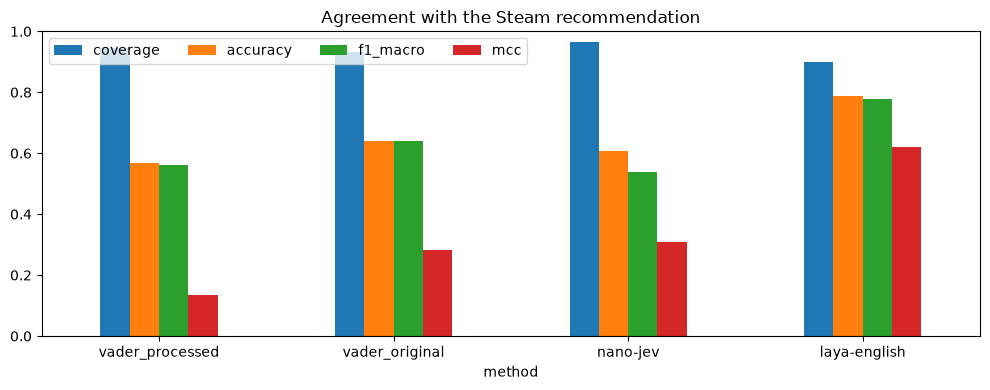

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
results[["coverage", "accuracy", "f1_macro", "mcc"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1)
ax.set_title("Agreement with the Steam recommendation")
ax.legend(loc="upper left", ncols=4)
fig.tight_layout()

Confusion matrices: rows are the reviewer's verdict, columns the model's prediction.

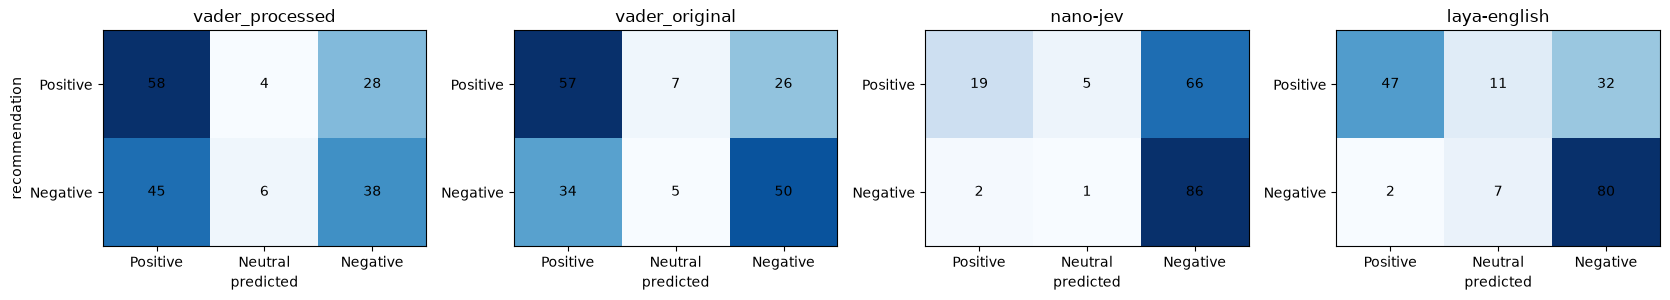

In [9]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(4.2 * len(METHODS), 3.6))
for ax, method in zip(axes, METHODS):
    matrix = confusion_matrix(scored["recommendation_label"], scored[method])
    ax.imshow(matrix.loc[["Positive", "Negative"]], cmap="Blues")
    for (i, j), value in pd.DataFrame(matrix.loc[["Positive", "Negative"]].to_numpy()).stack().items():
        ax.text(j, i, value, ha="center", va="center")
    ax.set_xticks(range(3), matrix.columns)
    ax.set_yticks(range(2), ["Positive", "Negative"])
    ax.set_title(method)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("recommendation")
fig.tight_layout()

### Does it depend on the game?

In [10]:
pd.concat(
    {name: compare_sentiment_methods(part, METHODS).set_index("method")["f1_macro"] for name, part in scored.groupby("preset")},
    axis=1,
)

,Counter_Strike,PUBG,SIMS
method,,,
vader_processed,0.569,0.592,0.520
vader_original,0.592,0.660,0.666
nano-jev,0.613,0.501,0.496
laya-english,0.833,0.678,0.819


### Where the best model and the reviewer disagree

Reviews the strongest transformer labels confidently opposite to the recommendation.
These are often sarcasm, long mixed reviews, or jokes.

In [11]:
best = results["f1_macro"].drop(["vader_processed", "vader_original"]).idxmax()
wrong = scored[
    scored[best].isin(["Positive", "Negative"]) & (scored[best] != scored["recommendation_label"])
].assign(abs_score=lambda df: df[f"{best}_score"].abs())
print("Model:", best)
with pd.option_context("display.max_colwidth", 200):
    display(wrong.nlargest(6, "abs_score")[["preset", "recommendation", best, f"{best}_score", "text"]])

Model: laya-english


,preset,recommendation,laya-english,laya-english_score,text
105,PUBG,Recommended,Negative,-0.976,FIX YOUR ♥♥♥♥♥♥♥ GAME YOU BLUEHOLE ♥♥♥♥♥ GET YOUR SERVERS IN CHECK REGION LOCK CHINA AND STOP BEING SO ♥♥♥♥♥♥♥ GREEDY YOU ♥♥♥♥♥♥♥♥
163,SIMS,Recommended,Negative,-0.974,Product received for free This game is like a leech sucking hours out of my life. It's like playing house as a kid but a version that's socially acceptable for someone in their 20s with too much ...
52,Counter_Strike,Recommended,Negative,-0.973,"You start up the game, thinking it will be a good session, only to be greeted with ""привет ♥♥♥♥♥"". Then you know you are in the wrong block in the town. You try to thing positively, for it to only..."
115,PUBG,Recommended,Negative,-0.953,This game gave me: · Acne · AIDS · allergies · Alice in Wonderland Syndrome (AIWS) · Alzheimer's disease · anal abscesses · anal Cancer · anal Itching · anal Tear · anxiety disorders · arthritis ...
118,PUBG,Recommended,Negative,-0.945,Too many cheaters most of them are the douyu chinese dudes and some vietnamese I think :// Stop adding skins etc and fix your d@mn game :// The game is great but meh for just adding skins and clea...
177,SIMS,Recommended,Negative,-0.942,"instead of buying the dlcs, simply live in a hole starting with $0, start without allowing technology, and cry yourself to sleep knowing you can't become a master artist in a week"


## Takeaways

On the saved run (180 reviews, seed 42, CPU):

- **`laya-english` agrees with the reviewers best**: macro F1 ≈ 0.78 and MCC ≈ 0.62, against
  ≈ 0.64 / 0.28 for the best VADER variant. It was also the slowest, about 4 minutes on a
  laptop CPU including loading, against 15 seconds for `nano-jev`.
- **Preprocessing designed for word counts hurts VADER**: on the original text VADER reaches
  F1 ≈ 0.64, on the processed text only ≈ 0.56, mostly because *not* and other negations are
  removed (see the examples in section 2). For sentiment, score the original `text` column.
- `nano-jev` is fast but labels most reviews *Negative* (see its confusion matrix), so it does not beat VADER here; it is a general-purpose model
  applied zero-shot.
- Numbers move with the sample and the seed; rerun with a larger `SAMPLE_PER_GAME` before
  drawing firm conclusions.
- The recommendation is not the same thing as text sentiment: people recommend games they
  complain about, and joke reviews are common. No model reaches perfect agreement, and the
  disagreements above are worth reading before trusting any score.
- License note: `nano-jev` weights are **non-commercial**; prefer a `laya-*` model for
  commercial work.